# FPS, задержка и память моделей

Сравнение включённых моделей через общий `Predictor`: CPU/CUDA, batch=1,
прогрев и отдельные процессы. [Подробный протокол и варианты измерений](scripts/benchmark/README.md).
Синтетический поток не подтверждает качество реального видео. Полный конвейер
защиты растений и HSV здесь не измеряется. Загрузка весов и обучение не запускаются.


In [1]:
from pathlib import Path
import sys

# Поддерживаются запуск из корня репозитория и из manual_notebooks.
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "scripts" / "common.py").is_file() else Path.cwd() / "manual_notebooks"
if not (NOTEBOOK_DIR / "scripts" / "common.py").is_file():
    raise RuntimeError("Open this notebook from the repository root or manual_notebooks")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from scripts import common as cmn
from scripts.workflows import enabled_specs
from scripts.benchmark import BenchmarkConfig, run_benchmarks, load_measurement_runs
from scripts.benchmark.plots import summary_table, plot_benchmarks, plot_fps_over_time, plot_latency_over_time, plot_series


## Конфигурация

`cmn.MODELS` остаётся единственным источником выбора. Для изменения набора задайте,
например, `cmn.MODELS["rf-detr-m"] = False` перед созданием `CHECKPOINTS`.
Для воспроизводимого сравнения замените пути удобных копий на веса конкретных запусков.
Изображения читаются до измерения, затем циклически используются в заданном порядке.


In [2]:
# Измените настройки перед запуском. Недоступные файлы вызывают явную ошибку.
CHECKPOINTS = {
    spec.id: cmn.TRAINED_WEIGHTS_DIR / f"{spec.id}.pt"
    for spec in enabled_specs()
}
IMAGE_PATHS = [cmn.DATASET_PATH / "images" / "image_000646.png"]
DEVICES = ["cpu"]  # Например: ["cpu", "cuda:0"].
PREDICTION_OPTIONS = {
    spec.id: ({"imgsz": 640, "conf": 0.25, "rect": True}
              if spec.backend == "ultralytics" else {"conf": 0.25})
    for spec in enabled_specs()
}
# RF-DETR использует разрешение checkpoint; несовместимый imgsz вызовет ошибку.
PROMPTS = {}  # JSON-совместимые подсказки для моделей, которым они нужны.
RUN_NOTES = ""  # Оборудование, режим питания, внешние ограничения.

WARMUP_FRAMES = 30
MEASUREMENT_SECONDS = 30
INPUT_RATES = (30,)
ORDER_SEED = 20261028
MEMORY_INTERVAL_SECONDS = 0.01
OUTPUT_ROOT = cmn.ROOT / "experiments" / "benchmarks"

for spec in enabled_specs():
    print(spec.id, spec.backend, CHECKPOINTS[spec.id], spec.unavailable_reason("predict") or "Ready for preflight")


yolov8n ultralytics /home/natsusa/academic/tobacco-article/weights/trained/yolov8n.pt Ready for preflight
yolo26n ultralytics /home/natsusa/academic/tobacco-article/weights/trained/yolo26n.pt Ready for preflight


## Прямое измерение

Запустите следующую ячейку, когда нужно измерить direct inference.
Поток запускается собственной ячейкой ниже. Флагов включения нет.
Длительность direct: `MEASUREMENT_SECONDS` на пару модель/устройство
плюс загрузка и прогрев. Для smoke test: 2 кадра прогрева, 1 секунда.

Прогрев выполняется перед каждым окном с теми же параметрами. Каждый завершённый
замер сразу сохраняется вместе с задержками, памятью и окружением.
Путь к каталогу и worker.log выводится до начала работы.

Индикатор считает завершённые замеры и показывает модель, устройство, режим,
стадию и время стадии. Интерфейс обновляется раз в секунду в родительском
процессе; внутри измеряемого цикла обновлений прогресса нет. Время стадии
служит подсказкой и не используется для расчёта метрик.


In [3]:
config = BenchmarkConfig(
    warmup_frames=WARMUP_FRAMES, duration_s=MEASUREMENT_SECONDS,
    input_rates=INPUT_RATES,
    direct=True, stream=False,
    seed=ORDER_SEED, memory_interval_s=MEMORY_INTERVAL_SECONDS,
)
DIRECT_RESULT_DIRECTORY = run_benchmarks(
    CHECKPOINTS, IMAGE_PATHS, devices=DEVICES, config=config,
    prediction_options=PREDICTION_OPTIONS, prompts=PROMPTS,
    output_root=OUTPUT_ROOT, notes=RUN_NOTES,
)
RESULT_DIRECTORY = DIRECT_RESULT_DIRECTORY
print(f"Completed: {RESULT_DIRECTORY}")


Benchmark directory: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104021Z-73e1036e


/home/natsusa/academic/tobacco-article/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Benchmarks:   0%|          | 0/2 [00:00]

Running yolov8n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104021Z-73e1036e/yolov8n-cpu/worker.log


Benchmarks:  50%|█████     | 1/2 [00:38, yolov8n / cpu / Direct / Saved (2s)]     

Running yolo26n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104021Z-73e1036e/yolo26n-cpu/worker.log


Benchmarks: 100%|██████████| 2/2 [01:13, Completed]                               

Completed: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104021Z-73e1036e


## Синтетический поток

Запустите эту ячейку для sweep по `INPUT_RATES`; direct-ячейку запускать не обязательно.
Длительность: `MEASUREMENT_SECONDS × len(INPUT_RATES)` на пару
модель/устройство плюс загрузка и прогрев. При запуске всех ячеек выполняются оба режима.


In [4]:
config = BenchmarkConfig(
    warmup_frames=WARMUP_FRAMES, duration_s=MEASUREMENT_SECONDS,
    input_rates=INPUT_RATES,
    direct=False, stream=True,
    seed=ORDER_SEED, memory_interval_s=MEMORY_INTERVAL_SECONDS,
)
STREAM_RESULT_DIRECTORY = run_benchmarks(
    CHECKPOINTS, IMAGE_PATHS, devices=DEVICES, config=config,
    prediction_options=PREDICTION_OPTIONS, prompts=PROMPTS,
    output_root=OUTPUT_ROOT, notes=RUN_NOTES,
)
RESULT_DIRECTORY = STREAM_RESULT_DIRECTORY
print(f"Completed: {RESULT_DIRECTORY}")


Benchmark directory: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104134Z-f0444f2c


Benchmarks:   0%|          | 0/2 [00:00]

Running yolov8n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104134Z-f0444f2c/yolov8n-cpu/worker.log


Benchmarks:  50%|█████     | 1/2 [00:39, yolov8n / cpu / Stream 30 FPS / Saved (2s)]     

Running yolo26n on cpu; log: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104134Z-f0444f2c/yolo26n-cpu/worker.log


Benchmarks: 100%|██████████| 2/2 [01:13, Completed]                                      

Completed: /home/natsusa/academic/tobacco-article/experiments/benchmarks/20261121T104134Z-f0444f2c


## Таблица и графики без повторного inference

Задайте `SAVED_RESULT_DIRECTORY`, чтобы открыть прошлый или прерванный запуск.
По умолчанию отображается последний выполненный режим. Можно указать
`DIRECT_RESULT_DIRECTORY` или `STREAM_RESULT_DIRECTORY` для выбора режима.
Processing FPS — число завершённых кадров / фактическая длительность окна.
Frame latency включает копирование и очередь, поэтому её обратная величина не FPS.

RSS — память всего worker, выборочный пик с интервалом 10 мс. CUDA allocated/reserved —
отдельные показатели аллокатора PyTorch после прогрева, не полная VRAM устройства.
Их нельзя складывать с RAM или друг с другом. На CPU CUDA-поля отсутствуют (`null`).
Каждый режим и входная частота измеряются один раз на пару модель/устройство.


,model_id,device,mode,input_fps,processed,elapsed_s,processing_fps,prediction_ms_mean,prediction_ms_median,prediction_ms_p95,...,dropped,generation_fps,drop_rate,rss_warm_mib,rss_sampled_peak_mib,cuda_allocated_mib_warm,cuda_reserved_mib_warm,cuda_allocated_mib_peak,cuda_reserved_mib_peak,rss_baseline_mib
0,yolo26n,cpu,stream,30,636,30.011057,21.192189,47.168759,43.424629,61.598349,...,264,30.022268,8.796758,807.992188,826.332031,NaN,NaN,NaN,NaN,553.800781
1,yolov8n,cpu,stream,30,517,30.009749,17.227735,58.030558,52.806336,72.385094,...,383,30.023577,12.762519,805.761719,824.796875,NaN,NaN,NaN,NaN,553.785156


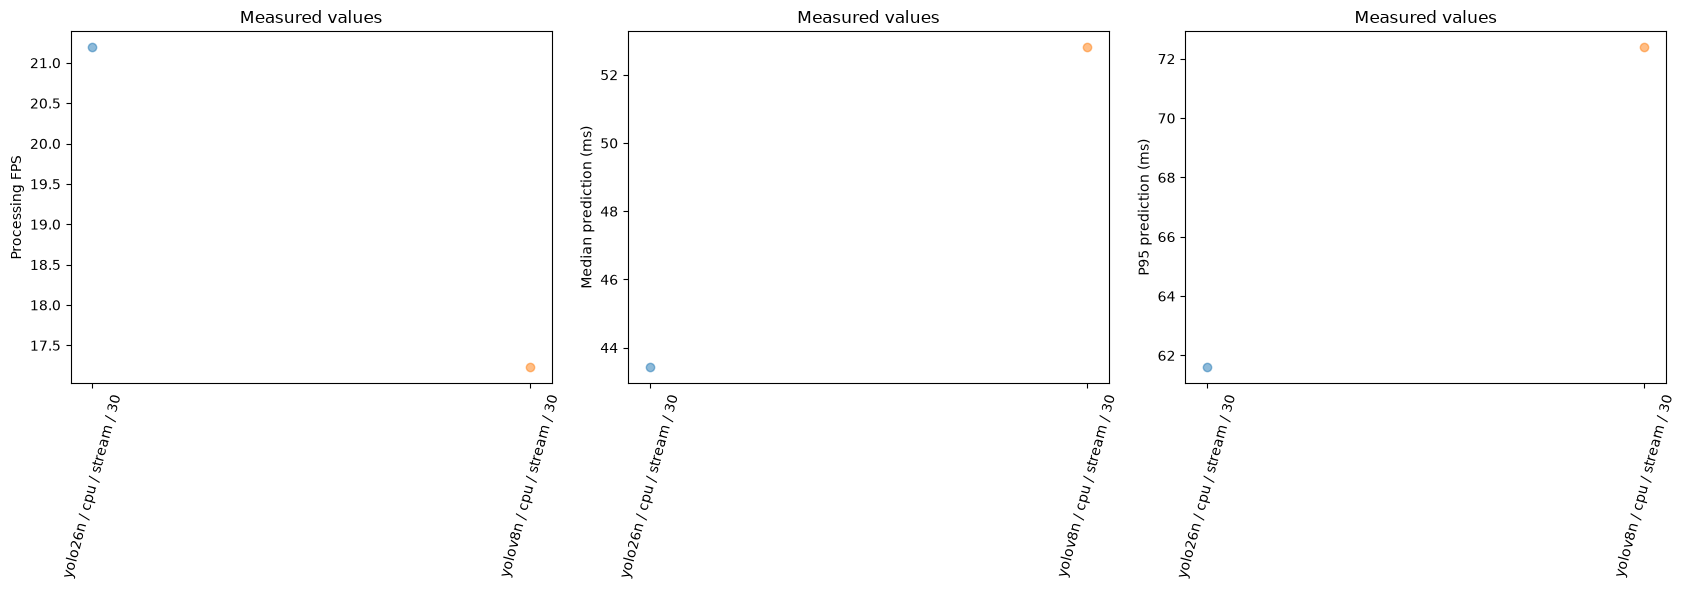

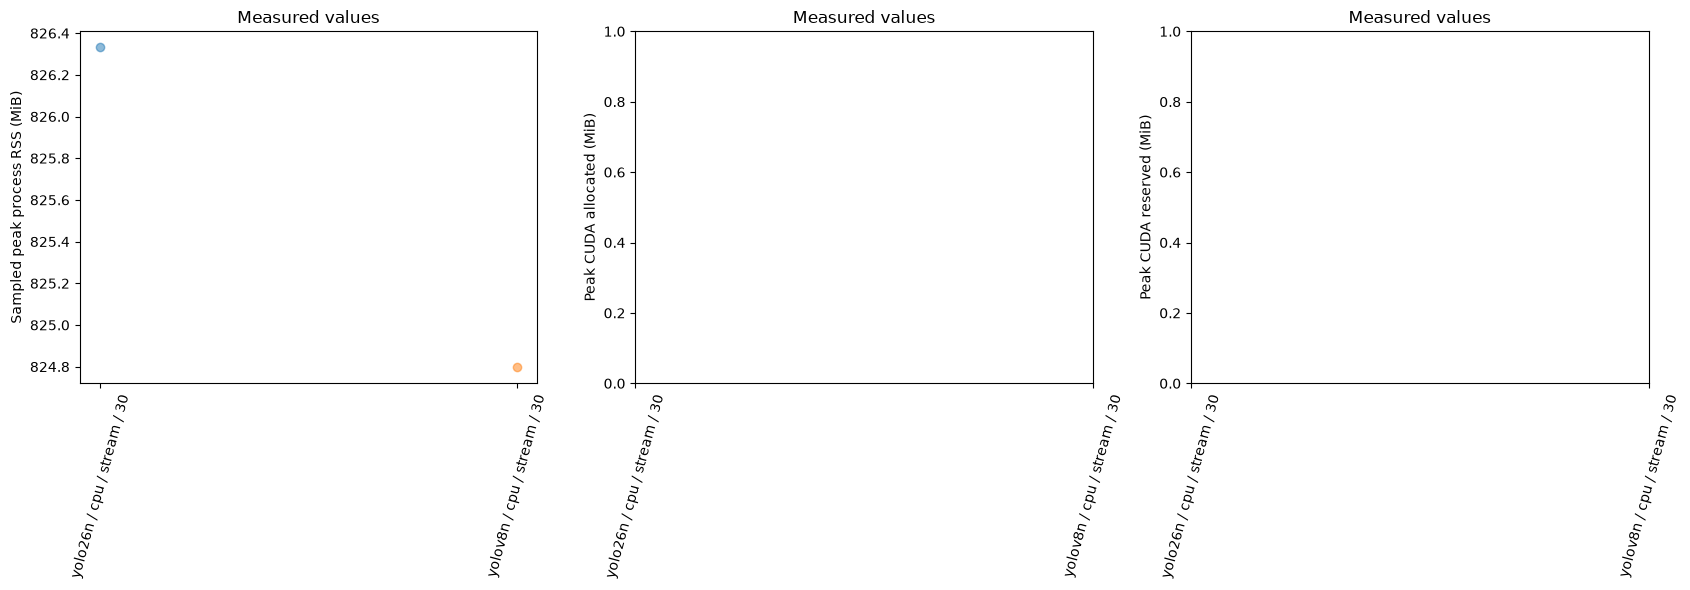

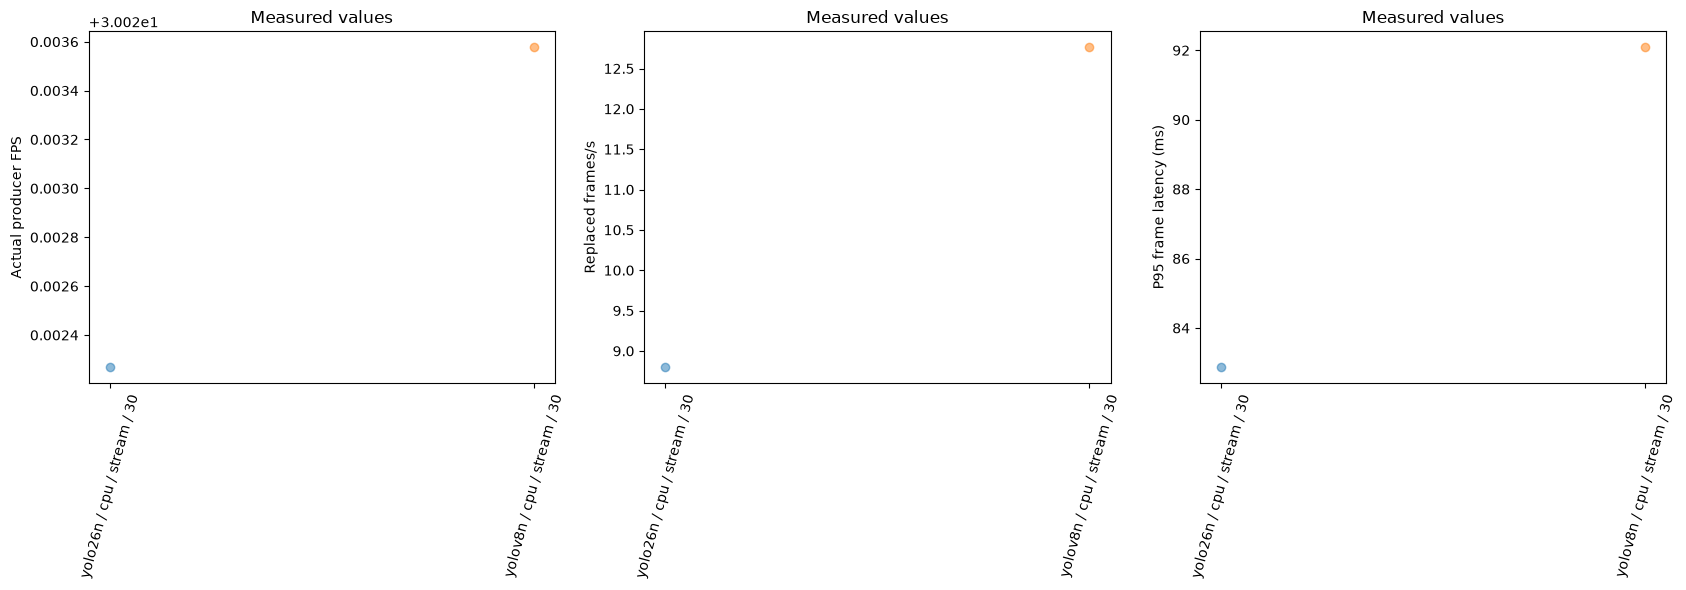

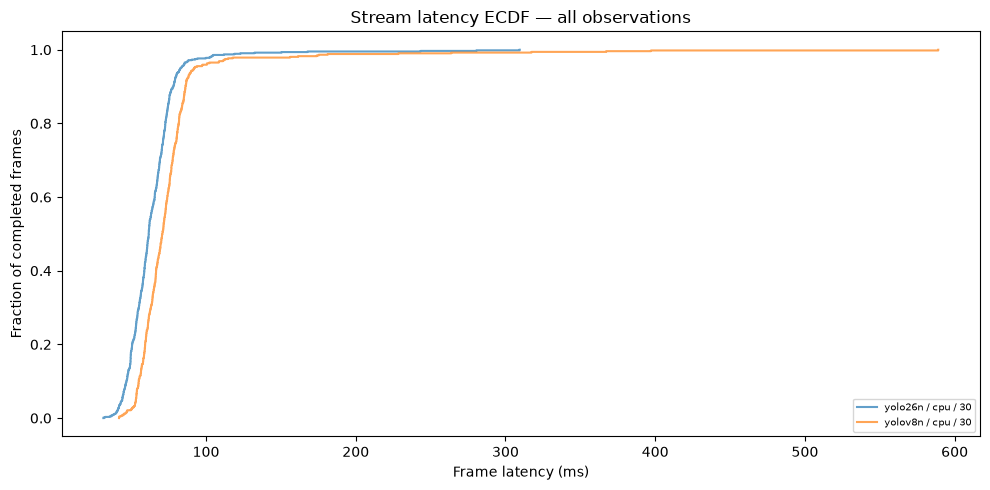

In [5]:
SAVED_RESULT_DIRECTORY = None  # Например: OUTPUT_ROOT / "20261121T120000Z-..."
results_path = SAVED_RESULT_DIRECTORY or globals().get("RESULT_DIRECTORY")
runs = load_measurement_runs(results_path) if results_path is not None else []
if results_path is not None:
    from IPython.display import display
    display(summary_table(results_path))
    plot_benchmarks(results_path)
else:
    print("Run the benchmark or set SAVED_RESULT_DIRECTORY to an existing results directory.")


## FPS во времени для каждой модели

Отдельная фигура для каждой пары модель/устройство, отдельная панель для каждого
режима/входной частоты. По X — секунды после прогрева, по Y — число завершённых
кадров в окне / длительность окна.
Последнее неполное окно делится на его фактическую длительность, пустые окна дают 0 FPS.
Изменяйте `FPS_BIN_SECONDS` для более подробного или сглаженного отображения.
Эта ячейка читает сохранённые результаты и не запускает inference.


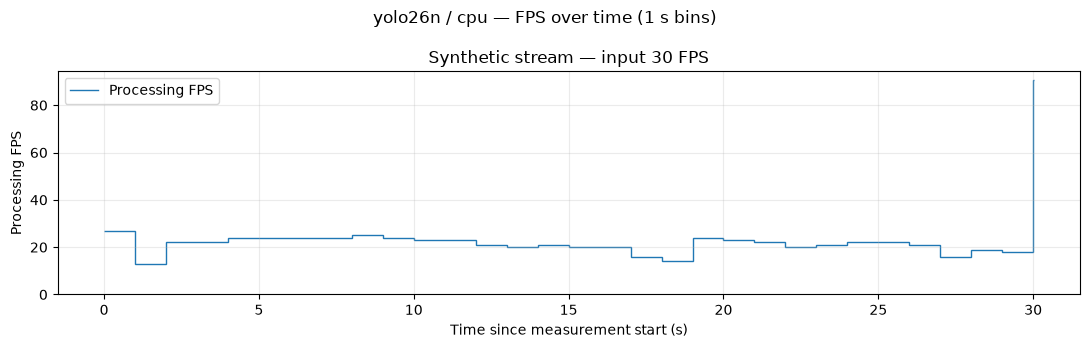

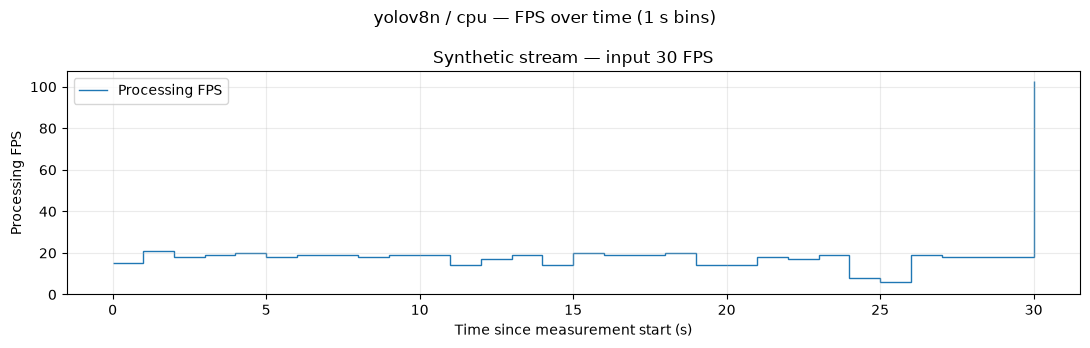

In [6]:
FPS_BIN_SECONDS = 1.0
if results_path is not None:
    plot_fps_over_time(runs, bin_seconds=FPS_BIN_SECONDS)
else:
    print("Select a results directory in the table cell above.")


## Задержка (мс) во времени для каждой модели

По X — время завершения кадра в секундах после начала измерения, по Y — задержка
в миллисекундах. Сплошная линия — время предсказания; для синтетического потока
пунктиром дополнительно показана задержка кадра с копированием и очередью.
Все наблюдения сохранены, без фильтрации выбросов
и усреднения. Используются те же сохранённые результаты, что и для FPS.


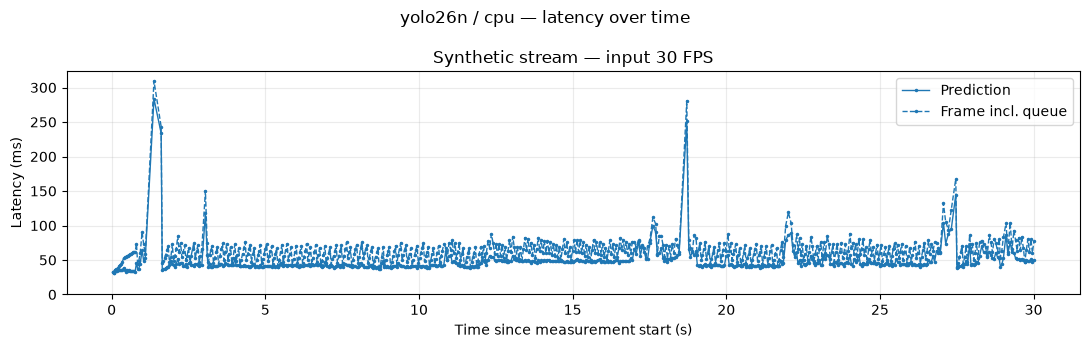

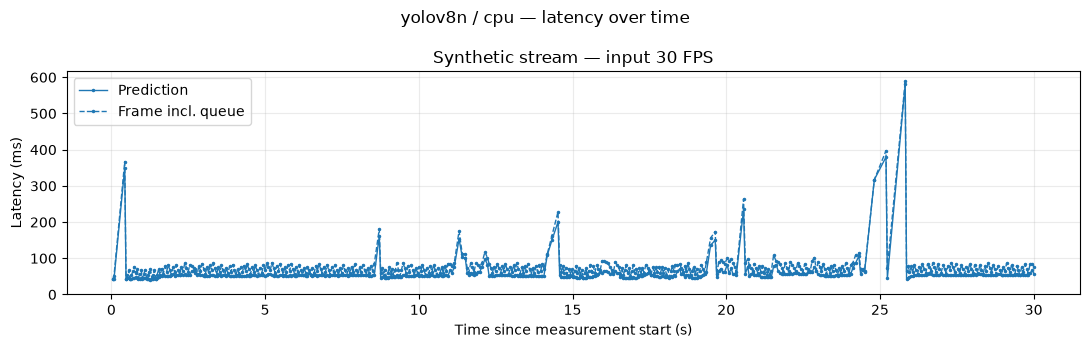

In [7]:
if results_path is not None:
    plot_latency_over_time(runs)
else:
    print("Select a results directory in the table cell above.")


## Работа с отдельным замером: срез и фильтрация

`runs` содержит отдельный `MeasurementRun` для каждой комбинации модели, устройства,
режима и запуска. Выберите `RUN_INDEX` по списку ниже. Времена заданы в секундах
от начала исходного замера; `slice(5, 10)` сохраняет эту шкалу.
Срез включает левую границу и исключает правую, кроме конца исходного замера.

`processing_fps` — число завершений / длительность выбранного окна.
`fps(kind="binned")` считает завершения по окнам; `fps(kind="instantaneous")`
использует обратный интервал между соседними завершениями внутри среза.
Это не обратная задержка кадра. Для пустого среза оконный FPS равен нулю,
а для менее двух завершений мгновенный ряд пуст.

`filter_outliers` создаёт новый ряд с маской исключения. Исходные времена,
значения и пропускная способность замера не меняются; исключённые точки дают
разрывы на графике. IQR вычисляется по ещё включённым значениям; при нулевом IQR
остаются только значения между Q1 и Q3. Фильтрация нужна для исследования графика,
а сохранённые сводки продолжают использовать все наблюдения.

Сначала делайте срез замера, затем вычисляйте FPS, чтобы пересчитать крайние окна.
Срез готового ряда (`series.slice(...)`) только обрезает отображение:
значения частично видимых интервалов остаются прежними.


0: yolo26n / cpu / stream / input 30 FPS / 30.01 s
1: yolov8n / cpu / stream / input 30 FPS / 30.01 s
Selected window: 5–10 s; processing FPS: 24.200


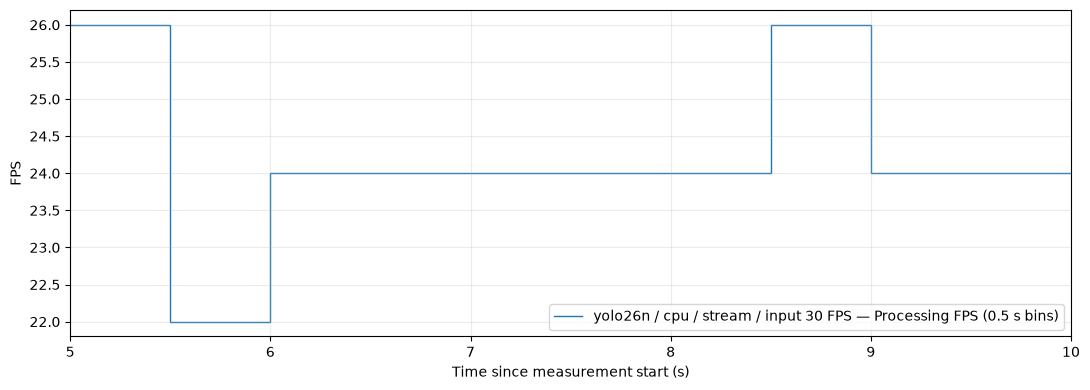

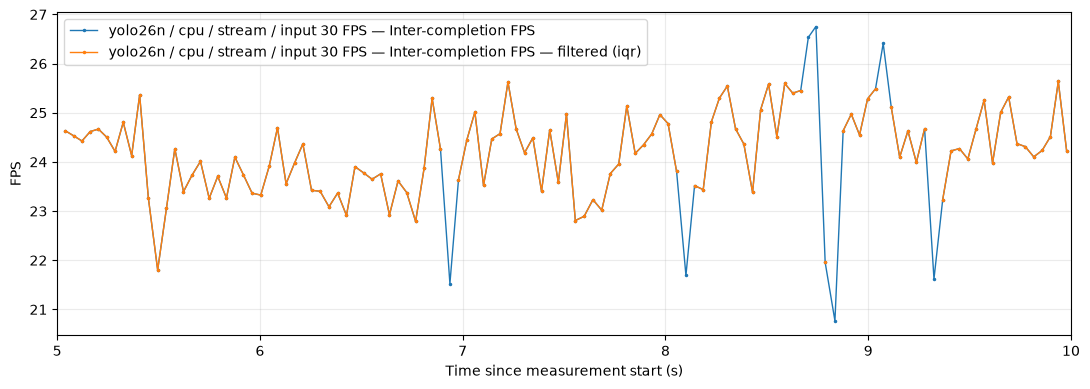

In [8]:
for index, candidate in enumerate(runs):
    print(f"{index}: {candidate.label} / {candidate.duration_s:.2f} s")

RUN_INDEX = 0
SLICE_START_SECONDS = 5.0
SLICE_END_SECONDS = 10.0

if runs:
    run = runs[RUN_INDEX]
    # Для короткого smoke test используем весь замер.
    selected = (run.slice(SLICE_START_SECONDS, SLICE_END_SECONDS)
                if run.end_s >= SLICE_END_SECONDS else run)
    print(f"Selected window: {selected.start_s:g}–{selected.end_s:g} s; "
          f"processing FPS: {selected.processing_fps:.3f}")

    binned = selected.fps(kind="binned", bin_seconds=0.5)
    instantaneous = selected.fps(kind="instantaneous")
    filtered = instantaneous.filter_outliers(method="iqr", factor=1.5)
    # Альтернатива с явными границами:
    # filtered = instantaneous.filter_outliers(method="bounds", minimum=1, maximum=100)
    plot_series(binned)
    plot_series([instantaneous, filtered])
    # Можно передать сам замер или его срез непосредственно в plot_series(selected).
    # Задержки также доступны: plot_series(selected.latency()).
else:
    print("Select a results directory in the table cell above.")
